# Phase 3: Corrected evaluation and Phase 4 holdout

This notebook supersedes the exploratory cost results in notebook 08. It preserves earlier outputs as research records. Signals use information through the last available close of each formation month and assume execution at that same close; future returns begin on the following trading day. Positions are held without daily rebalancing. Costs apply to each dollar bought or sold, including the initial investment. Trades and costs are measured relative to wealth before trading, with post-cost target weights.

The 30-stock universe is fixed and survivorship-biased. Same-close execution is optimistic. Current P/E is excluded because it would leak future information. The experiments are descriptive and in-sample, not evidence of future performance.

In [1]:
from pathlib import Path
import sys
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
root = Path.cwd()
if not (root / "src").is_dir(): root = root.parent
if not (root / "src/backtest.py").exists(): raise FileNotFoundError("Open from the project or notebooks folder")
sys.path.insert(0, str(root))
from src.backtest import run_factor_backtest, momentum_score
from src.metrics import calculate_performance_metrics
prices = pd.read_csv(root / "data/prices.csv", index_col=0, parse_dates=True).sort_index()
print(f"Prices: {prices.index.min().date()} to {prices.index.max().date()}; {len(prices.columns)} stocks")

Prices: 2018-01-02 to 2024-12-31; 30 stocks


## Costs and position sizing

All runs select the same top five momentum stocks. Inverse volatility uses up to 252 daily returns available at formation. Costs of 0, 5, 10, and 25 basis points apply to both buys and sells.

In [2]:
runs = {}
for weighting in ["equal", "inverse_volatility"]:
    for bps in [0, 5, 10, 25]:
        r, holdings, trades = run_factor_backtest(prices, partial(momentum_score, lookback=252), top_n=5, transaction_cost_bps=bps, weighting=weighting)
        runs[(weighting, bps)] = (r, holdings, trades)
for weighting in ["equal", "inverse_volatility"]:
    final = [float((1 + runs[(weighting, b)][0]).prod()) for b in [0, 5, 10, 25]]
    assert all(a >= b for a, b in zip(final, final[1:]))
    for b in [5, 10, 25]:
        assert runs[(weighting, b)][1]["holdings"].equals(runs[(weighting, 0)][1]["holdings"])
rows = []
for (weighting, bps), (r, _, trades) in runs.items():
    rows.append({"Weighting": weighting, "Cost (bps/side)": bps, **calculate_performance_metrics(r).to_dict(), "Ending $1": (1+r).prod(), "Mean monthly traded value": trades.gross_traded_value.mean()})
comparison = pd.DataFrame(rows).set_index(["Weighting", "Cost (bps/side)"])
comparison.round(4)

CAGR  Annual Return  Annual Volatility  \
Weighting          Cost (bps/side)                                             
equal              0                0.2254         0.2238             0.1981   
                   5                0.2219         0.2209             0.1980   
                   10               0.2184         0.2180             0.1979   
                   25               0.2081         0.2093             0.1976   
inverse_volatility 0                0.1864         0.1895             0.1901   
                   5                0.1827         0.1862             0.1899   
                   10               0.1790         0.1830             0.1898   
                   25               0.1679         0.1734             0.1894   

                                    Sharpe Ratio  Max Drawdown  Ending $1  \
Weighting          Cost (bps/side)                                          
equal              0                      1.1301       -0.1749     3.3290   
                   5                      1.1159       -0.1760     3.2734   
                   10                     1.1017       -0.1771     3.2187   
                   25                     1.0591       -0.1804     3.0600   
inverse_volatility 0                      0.9968       -0.1530     2.7491   
                   5                      0.9806       -0.1541     2.6984   
                   10                     0.9643       -0.1552     2.6487   
                   25                     0.9155       -0.1587     2.5048   

                                    Mean monthly traded value  
Weighting          Cost (bps/side)                             
equal              0                                   0.4746  
                   5                                   0.4746  
                   10                                  0.4746  
                   25                                  0.4744  
inverse_volatility 0                                   0.5243  
                   5                                   0.5242  
                   10                                  0.5241  
                   25                                  0.5239

## SPY comparison on matching dates

SPY adjusted-close data is downloaded on execution. This cell does not save data. Adjusted prices include distributions under the provider's adjustment method. The strategy and SPY returns below share the same monthly dates.

In [3]:
strategy = runs[("equal", 10)][0]
start = runs[("equal", 10)][2].formation_date.iloc[0]
spy = yf.download("SPY", start=start.strftime("%Y-%m-%d"), end=(strategy.index[-1] + pd.Timedelta(days=3)).strftime("%Y-%m-%d"), auto_adjust=True, progress=False)
if spy.empty: raise RuntimeError("SPY download failed; rerun when data access is available.")
close = spy["Close"]["SPY"] if isinstance(spy.columns, pd.MultiIndex) else spy["Close"]
monthly = close.resample("ME").last()
spy_returns = monthly.pct_change(fill_method=None).reindex(strategy.index)
if spy_returns.isna().any(): raise ValueError("Missing SPY observations on strategy dates")
common = pd.concat([runs[("equal",0)][0].rename("Momentum gross"), strategy.rename("Momentum 10 bps"), spy_returns.rename("SPY")], axis=1).dropna()
assert len(common) == len(strategy)
pd.DataFrame({col: calculate_performance_metrics(common[col]) for col in common}).T.round(4)

,CAGR,Annual Return,Annual Volatility,Sharpe Ratio,Max Drawdown
Momentum gross,0.2254,0.2238,0.1981,1.1301,-0.1749
Momentum 10 bps,0.2184,0.2180,0.1979,1.1017,-0.1771
SPY,0.1583,0.1627,0.1730,0.9404,-0.2393


## Rolling 12-month results

Rolling return compounds 12 monthly returns. Rolling volatility annualizes the standard deviation of those monthly returns. Rolling drawdown measures the largest loss from a prior peak within each window, starting with $1.

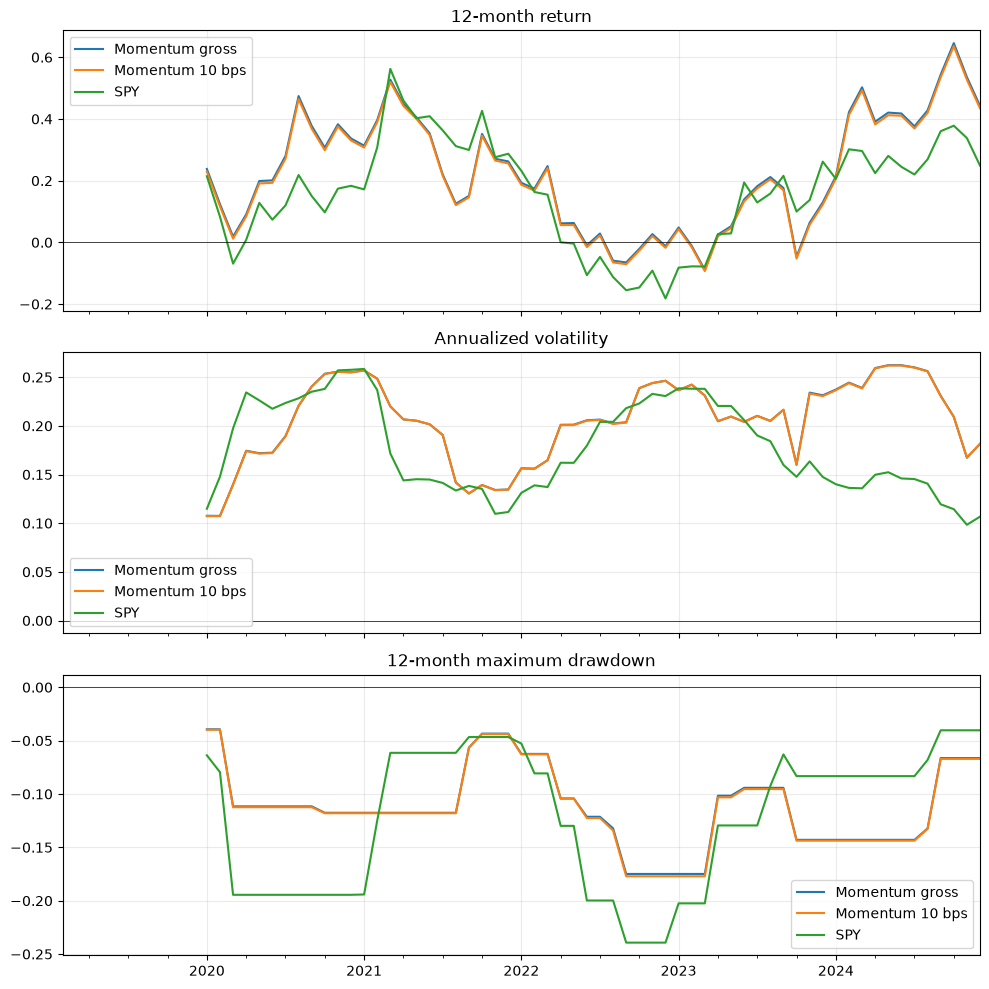

In [4]:
def window_drawdown(r):
    wealth = np.r_[1.0, np.cumprod(1 + np.asarray(r))]
    return np.min(wealth / np.maximum.accumulate(wealth) - 1)
rolling_return = (1 + common).rolling(12).apply(np.prod, raw=True) - 1
rolling_vol = common.rolling(12).std() * np.sqrt(12)
rolling_drawdown = common.rolling(12).apply(window_drawdown, raw=True)
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for data, title, ax in zip([rolling_return, rolling_vol, rolling_drawdown], ["12-month return", "Annualized volatility", "12-month maximum drawdown"], axes):
    data.plot(ax=ax, title=title); ax.axhline(0, color="black", linewidth=0.5); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## Chronological Phase 4 holdout setup

Each row is a stock at a month-end formation date. Momentum and volatility use past observations only; the label is that stock's next month return. Formation dates through 2021 are training/development data. Dates from 2022 onward are an untouched holdout; the final development label ends no later than December 2021, so it cannot overlap the holdout. Do not select models or features using holdout results. Static P/E and current-universe bias remain unresolved.

In [5]:
monthly_prices = prices.resample("ME").last()
momentum = prices.pct_change(252, fill_method=None).resample("ME").last()
volatility = prices.pct_change(fill_method=None).rolling(252, min_periods=252).std().resample("ME").last() * np.sqrt(252)
forward = monthly_prices.shift(-1).div(monthly_prices).sub(1)
def long(frame, name):
    return frame.rename_axis(index="formation_date", columns="ticker").stack().rename(name)
features = pd.concat([long(momentum, "momentum_252d"), long(volatility, "volatility_252d"), long(forward, "next_month_return")], axis=1).dropna()
# Purge December 2021, whose label ends during January 2022.
train = features.loc[features.index.get_level_values("formation_date") < "2021-12-01"].copy()
holdout = features.loc[features.index.get_level_values("formation_date") >= "2022-01-01"].copy()
assert train.index.get_level_values("formation_date").max() < pd.Timestamp("2021-12-01")
assert holdout.index.get_level_values("formation_date").min() >= pd.Timestamp("2022-01-01")
print(f"Development: {len(train)} rows; holdout: {len(holdout)} rows")
print("Development through", train.index.get_level_values("formation_date").max().date(), "| Holdout from", holdout.index.get_level_values("formation_date").min().date())
train.head()

Development: 1050 rows; holdout: 1050 rows
Development through 2021-11-30 | Holdout from 2022-01-31


momentum_252d  volatility_252d  next_month_return
formation_date ticker                                                   
2019-01-31     AAPL         0.011791         0.316636           0.044776
               AMGN         0.006996         0.241817           0.023728
               AMZN         0.195372         0.372391          -0.045906
               AXP          0.056164         0.245542           0.049075
               BA           0.164278         0.319333           0.146648